# CPR Score Justification Analysis

Prove to Client Relationship team that the cohort-based **CPRScore** produced at report date **T** correctly predicts which clients' loans prepay faster/slower than their **peer cohort** over the following months.

Two questions addressed:

1. **Predictive validity** — Did clients with high CPRScore at T actually prepay faster than their peer cohorts over the next N months? Uses the same **self-included** cohort-benchmark methodology as the production score, applied to forward data.

2. **Rank stability** — How often does a client's classification (Favourable / Neutral / Unfavourable) change when the score is re-run months later?

Uses the production reporter (`B2B_functions_cohort_score.py`) **unchanged**, and re-implements the identical cohort-CPR math on forward-window data in this notebook.

Kernel: **Python (B2B)** (env `B2B`).

## 0. USER INPUTS

All configurable parameters live in one cell — change these to re-run under different scenarios.

In [1]:
from datetime import date

# ---------- Q1: Predictive validity ----------
T_REPORT       = date(2025, 6, 30)   # Report month at which CPRScore is measured
FORWARD_MONTHS = 12                  # Length of forward window (months)
MIN_CPR_LOANS_Q1 = 100               # Min CPRLoanct at T to include client in correlation

# ---------- Q2: Rank stability ----------
STABILITY_T1        = date(2024, 6, 30)   # T1 (earlier scoring date)
STABILITY_H_MONTHS  = 12                  # T2 = T1 + this many months (default 12)
LOW_CUTOFF          = 0.8                 # CPRScore <= this  -> Favourable
HIGH_CUTOFF         = 1.2                 # CPRScore >= this  -> Unfavourable
MIN_STABILITY_LOANS = 50                  # Min CPRLoanct at BOTH dates to include client

# Sensitivity grids
CUTOFF_GRID  = [(0.70, 1.30), (0.75, 1.25), (0.80, 1.20), (0.85, 1.15), (0.90, 1.10)]
HORIZON_GRID = [6, 12, 18]                # T2 = T1 + h months, for each h

# ---------- Output ----------
OUTPUT_PATH = r"E:\Development\Shashi\B2B-Pricing-Model\Cohort_Analysis\B2B_reporting_raw"
OUTPUT_FILE = f"CPR_score_justification_{T_REPORT.strftime('%Y%m%d')}.xlsx"

print(f"Q1 - Report month       : {T_REPORT}")
print(f"Q1 - Forward window     : {FORWARD_MONTHS} months")
print(f"Q1 - Min CPRLoanct      : {MIN_CPR_LOANS_Q1}")
print()
print(f"Q2 - Base pair          : T1 = {STABILITY_T1}, T2 = T1 + {STABILITY_H_MONTHS}mo")
print(f"Q2 - Classification     : Favourable <= {LOW_CUTOFF} | Unfavourable >= {HIGH_CUTOFF}")
print(f"Q2 - Min stability loans: {MIN_STABILITY_LOANS}")
print(f"Q2 - Cutoff grid        : {CUTOFF_GRID}")
print(f"Q2 - Horizon grid (mo)  : {HORIZON_GRID}")
print()
print(f"Output -> {OUTPUT_PATH}\\{OUTPUT_FILE}")

Q1 - Report month       : 2025-06-30
Q1 - Forward window     : 12 months
Q1 - Min CPRLoanct      : 100

Q2 - Base pair          : T1 = 2024-06-30, T2 = T1 + 12mo
Q2 - Classification     : Favourable <= 0.8 | Unfavourable >= 1.2
Q2 - Min stability loans: 50
Q2 - Cutoff grid        : [(0.7, 1.3), (0.75, 1.25), (0.8, 1.2), (0.85, 1.15), (0.9, 1.1)]
Q2 - Horizon grid (mo)  : [6, 12, 18]

Output -> E:\Development\Shashi\B2B-Pricing-Model\Cohort_Analysis\B2B_reporting_raw\CPR_score_justification_20250630.xlsx


## 1. Imports & SQL connection

In [2]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, pearsonr
from sqlalchemy import text

# Local functions folder (unchanged production module)
FUNCTIONS_DIR = os.path.join(os.getcwd(), 'functions')
if FUNCTIONS_DIR not in sys.path:
    sys.path.insert(0, FUNCTIONS_DIR)

import B2B_functions_cohort_score as bf
from B2B_functions_cohort_score import (
    sql_connection, B2BPricingReporter, DateHelpers, MIN_COHORT_LOANS,
)

%load_ext autoreload
%autoreload 2

# Chart style — clean, business-friendly
plt.rcParams.update({
    'figure.figsize': (12, 5.5),
    'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10,
})
NAVY  = '#003865'
RED   = '#C8102E'
GRAY  = '#7B8B94'
GREEN = '#4A7729'
AMBER = '#E67E22'

print('B2B_functions_cohort_score loaded from:', bf.__file__)
print('MIN_COHORT_LOANS (production threshold):', MIN_COHORT_LOANS)

B2B_functions_cohort_score loaded from: e:\Development\Shashi\B2B-Pricing-Model\repo\python\functions\B2B_functions_cohort_score.py
MIN_COHORT_LOANS (production threshold): 10


In [3]:
engine = sql_connection()
engine

Engine(mssql+pyodbc:///?odbc_connect=DRIVER%3D%7BODBC+Driver+17+for+SQL+Server%7D%3BSERVER%3DVMC2VMDBRADC01P%3BDATABASE%3DAnalytics_Rpt%3BTrusted_Connection%3Dyes)

## 2. Q1 — Predictive Validity Test

Freeze the loans that produced the T-score → observe their forward performance → compute the same cohort-adjusted CPRScore on the forward window (self-included cohort benchmark, matching production formula) → correlate T-score with Forward-score.

### 2.1 — Score at T (production reporter, unchanged)

In [4]:
print(f'Running production reporter at T = {T_REPORT} ...')
reporter_T = B2BPricingReporter(engine).load(report_as_of_dt=T_REPORT)

# Client-level scores from the 'Client' metric slice
metrics_T = reporter_T.run_all_metrics(product='All')
client_scores_T = (
    metrics_T[metrics_T['MetricName'] == 'Client']
    [['MetricValue', 'CPRLoanct', 'FundedLoanAmt', 'ActualCPR', 'ModelCPR', 'CPRScore']]
    .rename(columns={'MetricValue': 'Client'})
    .reset_index(drop=True)
)

n_scored = len(client_scores_T)
n_qual   = (client_scores_T['CPRLoanct'] >= MIN_CPR_LOANS_Q1).sum()
print(f'\nClients scored at T                : {n_scored:,}')
print(f'Clients w/ CPRLoanct >= {MIN_CPR_LOANS_Q1:>4}       : {n_qual:,}')
print(f'\nTop-10 clients by CPRLoanct @ T:')
client_scores_T.nlargest(10, 'CPRLoanct')[
    ['Client', 'CPRLoanct', 'ActualCPR', 'ModelCPR', 'CPRScore']
].round({'ActualCPR': 3, 'ModelCPR': 3, 'CPRScore': 2})

Running production reporter at T = 2025-06-30 ...
Report as of  : 2025-06-30
Funding window: 2024-07-01  →  2025-06-30
Score window  : 1900-01-01  →  2025-06-30

Clients scored at T                : 783
Clients w/ CPRLoanct >=  100       : 660

Top-10 clients by CPRLoanct @ T:


,Client,CPRLoanct,ActualCPR,ModelCPR,CPRScore
26,EVERETT FINANCIAL INC DBA SUPREME LENDING,221861.0,0.073,0.064,1.14
29,CANOPY MORTGAGE LLC,155734.0,0.039,0.050,0.78
1,THE LOAN STORE INC,147638.0,0.049,0.030,1.65
12,PARAMOUNT RESIDENTIAL MORTGAGE GROUP INC,125870.0,0.054,0.038,1.43
33,BAY EQUITY LLC,118628.0,0.059,0.052,1.14
0,LOANDEPOTCOM LLC,110773.0,0.069,0.036,1.95
23,NFM LENDING LLC,99567.0,0.057,0.036,1.57
11,FIRST COMMUNITY MORTGAGE INC,85103.0,0.082,0.084,0.98
36,LOWER LLC,84258.0,0.077,0.071,1.08
102,AMERICAN FINANCIAL NETWORK INC,82307.0,0.052,0.053,0.99


### 2.2 — Bulk-pull B2BPricingHist and B2B_revamp_cohorts for T + forward window

One large pull for `AsofDt BETWEEN T AND T + FORWARD_MONTHS`. All filtering and frozen-loan-set derivation is done in Python (avoids per-loan SQL).

In [5]:
end_fwd_dt = DateHelpers.eomonth(T_REPORT, FORWARD_MONTHS)
print(f'Pulling B2BPricingHist for AsofDt BETWEEN {T_REPORT} AND {end_fwd_dt} ...')

perf_sql = text("""
    SELECT a.LoanNum, a.Client, a.AsofDt, a.BeginPrinBal, a.EndPrinBal,
           a.ProductCategory, a.PropState
    FROM Analytics_Rpt.md.B2BPricingHist a
    INNER JOIN ADM.ODS.vwOrigLoan b ON a.LoanNum = b.LoanNum
    WHERE a.AsofDt BETWEEN :begin_dt AND :end_dt
      AND a.FundedLoanAmt > 0
      AND a.Client IS NOT NULL
      AND b.MortgageType <> 'Reverse'
      AND NOT EXISTS (
          SELECT 1 FROM Analytics_Rpt.md.B2BPricingHist x
          WHERE x.LoanNum = a.LoanNum
            AND (x.ResolType = 'XFER' OR x.Channel = 'Bulk')
      )
""")
perf_bulk = pd.read_sql(perf_sql, engine, params={'begin_dt': T_REPORT, 'end_dt': end_fwd_dt})
perf_bulk['AsofDt'] = pd.to_datetime(perf_bulk['AsofDt'])
print(f'  perf_bulk rows    : {len(perf_bulk):,}')

print(f'\nPulling B2B_revamp_cohorts for same window ...')
coh_sql = text("""
    SELECT LoanNum, AsofDt, cohort_unique_ID AS Cohort_ID
    FROM Analytics_Rpt.md.B2B_revamp_cohorts
    WHERE AsofDt BETWEEN :begin_dt AND :end_dt
""")
cohorts_bulk = pd.read_sql(coh_sql, engine, params={'begin_dt': T_REPORT, 'end_dt': end_fwd_dt})
cohorts_bulk['AsofDt'] = pd.to_datetime(cohorts_bulk['AsofDt'])
print(f'  cohorts_bulk rows : {len(cohorts_bulk):,}')
print(f'  unique cohort IDs : {cohorts_bulk["Cohort_ID"].nunique():,}')
print(f'  months covered    : {cohorts_bulk["AsofDt"].nunique()}')

Pulling B2BPricingHist for AsofDt BETWEEN 2025-06-30 AND 2026-06-30 ...
  perf_bulk rows    : 4,217,601

Pulling B2B_revamp_cohorts for same window ...
  cohorts_bulk rows : 4,218,854
  unique cohort IDs : 160
  months covered    : 13


### 2.3 — Freeze T-vintage loan set and build the forward panel

In [6]:
T_ts = pd.Timestamp(T_REPORT)

# Frozen loan set = distinct LoanNums with a snapshot row at AsofDt = T
frozen = (
    perf_bulk[perf_bulk['AsofDt'] == T_ts]
    [['Client', 'LoanNum']]
    .drop_duplicates()
    .reset_index(drop=True)
)
print(f'Frozen loans @ T  : {len(frozen):,} across {frozen["Client"].nunique():,} clients')

# Forward panel: AsofDt > T, restricted to frozen loans (inner join on LoanNum)
perf_fwd = (
    perf_bulk[perf_bulk['AsofDt'] > T_ts]
    .merge(frozen[['LoanNum']], on='LoanNum', how='inner')
    .copy()
)
# Attach monthly Cohort_ID (a loan's cohort can drift month-to-month, mirrors production)
perf_fwd = perf_fwd.merge(cohorts_bulk, on=['LoanNum', 'AsofDt'], how='left')

n_lm     = len(perf_fwd)
n_lm_coh = perf_fwd['Cohort_ID'].notna().sum()
print(f'Forward loan-months (frozen set): {n_lm:,}')
print(f'  -> with a Cohort_ID           : {n_lm_coh:,} ({100*n_lm_coh/n_lm:.1f}%)')
print(f'  -> PLS/unmapped (excluded)    : {n_lm - n_lm_coh:,} ({100*(n_lm-n_lm_coh)/n_lm:.1f}%)')

# Loan-months per forward AsofDt (DQ view)
lm_per_month = (
    perf_fwd.groupby('AsofDt')
    .agg(UniqueLoans=('LoanNum', 'nunique'),
         LoanMonths=('LoanNum', 'size'),
         BeginUPB=('BeginPrinBal', 'sum'))
    .reset_index()
)
lm_per_month['BeginUPB_$M'] = (lm_per_month['BeginUPB']/1e6).round(1)
lm_per_month.drop(columns='BeginUPB', inplace=True)
print(f'\nForward months observed: {len(lm_per_month)}  (expected = {FORWARD_MONTHS})')
lm_per_month

Frozen loans @ T  : 276,451 across 965 clients
Forward loan-months (frozen set): 3,111,676
  -> with a Cohort_ID           : 3,102,889 (99.7%)
  -> PLS/unmapped (excluded)    : 8,787 (0.3%)

Forward months observed: 12  (expected = 12)


,AsofDt,UniqueLoans,LoanMonths,BeginUPB_$M
0,2025-07-31,274877,274877,83531.6
1,2025-08-31,270417,270417,81881.9
2,2025-09-30,268795,268795,81208.3
3,2025-10-31,266988,266988,80423.1
4,2025-11-30,264447,264447,79276.2
5,2025-12-31,262318,262318,78327.4
6,2026-01-31,255940,255940,76118.0
7,2026-02-28,254206,254206,75325.8
8,2026-03-31,252046,252046,74342.4
9,2026-04-30,249332,249332,73157.2


### 2.4 — Compute forward CPRScore per client (same self-included cohort math as production)

- Cell aggregation: for each `(Client × Cohort_ID)` cell, $\text{ActualCPR}_{gc} = 1 - (\Sigma \text{EndBal} / \Sigma \text{BeginBal})^{12}$
- Cohort benchmark (**self-included**, matches production): $\text{ModelCPR}_{\text{cohort}} = \Sigma(\text{ActualCPR}_{gc} \cdot \text{LoanCt}_{gc}) / \Sigma \text{LoanCt}_{gc}$ across ALL clients' cells in that cohort
- Client rollup: $\text{ForwardCPRScore} = \Sigma(\text{ActualCPR}_{gc} \cdot \text{LoanCt}_{gc}) / \Sigma(\text{ModelCPR}_{\text{cohort}} \cdot \text{LoanCt}_{gc})$

In [7]:
# Restrict to cohort-assigned loan-months (PLS excluded — production rule)
p_c = perf_fwd[perf_fwd['Cohort_ID'].notna()].copy()

# ---- Step 1: (Client x Cohort_ID) cell aggregation ---------------------
gc = p_c.groupby(['Client', 'Cohort_ID'], dropna=False).agg(
    LoanCt_gc  = ('LoanNum',      'size'),      # loan-months in cell
    BeginBal_gc= ('BeginPrinBal', 'sum'),
    EndBal_gc  = ('EndPrinBal',   'sum'),
).reset_index()
gc['ActualCPR_gc'] = np.where(
    gc['BeginBal_gc'] > 0,
    1 - (gc['EndBal_gc'] / gc['BeginBal_gc']) ** 12,
    np.nan,
)

# Same min-loan-count filter as production (default 10)
gc = gc[gc['LoanCt_gc'] >= MIN_COHORT_LOANS].dropna(subset=['ActualCPR_gc'])

# ---- Step 2: cohort benchmark (SELF-INCLUDED, matches production) ------
cohort_bench = (
    gc.groupby('Cohort_ID', dropna=False)
    .apply(lambda g: pd.Series({
        'ModelCPR_cohort': (g['ActualCPR_gc'] * g['LoanCt_gc']).sum() / g['LoanCt_gc'].sum(),
        'PeersLoanCt':     g['LoanCt_gc'].sum(),
    }))
    .reset_index()
)
gc = gc.merge(cohort_bench, on='Cohort_ID', how='left')

# ---- Step 3: roll up to client ----------------------------------------
client_fwd = gc.groupby('Client', dropna=False).apply(lambda g: pd.Series({
    'ActualCPR_fwd_wt':  (g['ActualCPR_gc']    * g['LoanCt_gc']).sum(),
    'ModelCPR_fwd_wt':   (g['ModelCPR_cohort'] * g['LoanCt_gc']).sum(),
    'LoanMonths_fwd':     g['LoanCt_gc'].sum(),
    'CohortCount_fwd':    g['Cohort_ID'].nunique(),
})).reset_index()

client_fwd['ActualCPR_fwd']   = client_fwd['ActualCPR_fwd_wt'] / client_fwd['LoanMonths_fwd']
client_fwd['ModelCPR_fwd']    = client_fwd['ModelCPR_fwd_wt']  / client_fwd['LoanMonths_fwd']
client_fwd['ForwardCPRScore'] = client_fwd['ActualCPR_fwd'] / client_fwd['ModelCPR_fwd']

# Naive (unadjusted) forward CPR = raw prepay speed across ALL forward loan-months
naive = perf_fwd.groupby('Client', dropna=False).agg(
    UniqueLoansFwd=('LoanNum',      'nunique'),
    BeginBal_all  =('BeginPrinBal', 'sum'),
    EndBal_all    =('EndPrinBal',   'sum'),
).reset_index()
naive['ActualCPR_fwd_naive'] = np.where(
    naive['BeginBal_all'] > 0,
    1 - (naive['EndBal_all'] / naive['BeginBal_all']) ** 12,
    np.nan,
)
client_fwd = client_fwd.merge(
    naive[['Client', 'UniqueLoansFwd', 'ActualCPR_fwd_naive']],
    on='Client', how='left',
)

print(f'Clients with forward-scoring : {len(client_fwd):,}')
client_fwd.sort_values('LoanMonths_fwd', ascending=False).head()

C:\Users\kanshash\AppData\Local\Temp\3\ipykernel_11948\3174637004.py:22: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({
C:\Users\kanshash\AppData\Local\Temp\3\ipykernel_11948\3174637004.py:31: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  client_fwd = gc.groupby('Client', dropna=False).apply(lambda g: pd.Series({


Clients with forward-scoring : 925


,Client,ActualCPR_fwd_wt,ModelCPR_fwd_wt,LoanMonths_fwd,CohortCount_fwd,ActualCPR_fwd,ModelCPR_fwd,ForwardCPRScore,UniqueLoansFwd,ActualCPR_fwd_naive
659,PHH MORTGAGE CORPORATION,17424.304835,18840.813865,186149.0,155.0,0.093604,0.101214,0.924817,16281,0.091369
825,THE LOAN STORE INC,5557.787755,3746.998559,87635.0,131.0,0.063420,0.042757,1.483264,7654,0.113624
260,EVERETT FINANCIAL INC DBA SUPREME LENDING,5867.152588,5088.572769,73910.0,115.0,0.079382,0.068848,1.153006,6446,0.071309
505,LOANDEPOTCOM LLC,5339.013930,3129.969144,70109.0,140.0,0.076153,0.044644,1.705772,6586,0.155673
493,LENNAR MORTGAGE LLC,3355.158421,2401.390388,60723.0,123.0,0.055254,0.039547,1.397173,5418,0.058943


### 2.5 — Headline validation stats: T-score vs Forward-score

In [8]:
q1 = client_scores_T.merge(client_fwd, on='Client', how='inner')

# Universe for correlation — clients with meaningful T-side loan count
q1_ok = q1[q1['CPRLoanct'] >= MIN_CPR_LOANS_Q1].copy()
q1_ok = q1_ok.dropna(subset=['ForwardCPRScore', 'CPRScore', 'ActualCPR_fwd_naive'])

# Correlations
sp_rel,   _ = spearmanr(q1_ok['CPRScore'], q1_ok['ForwardCPRScore'])
pr_rel,   _ = pearsonr (q1_ok['CPRScore'], q1_ok['ForwardCPRScore'])
sp_naive, _ = spearmanr(q1_ok['CPRScore'], q1_ok['ActualCPR_fwd_naive'])
pr_naive, _ = pearsonr (q1_ok['CPRScore'], q1_ok['ActualCPR_fwd_naive'])

def wcorr(x, y, w):
    x, y, w = np.asarray(x, float), np.asarray(y, float), np.asarray(w, float)
    mx, my = np.average(x, weights=w), np.average(y, weights=w)
    cov = np.average((x-mx)*(y-my), weights=w)
    return cov / np.sqrt(np.average((x-mx)**2, weights=w) * np.average((y-my)**2, weights=w))

wp_rel   = wcorr(q1_ok['CPRScore'], q1_ok['ForwardCPRScore'],     q1_ok['CPRLoanct'])
wp_naive = wcorr(q1_ok['CPRScore'], q1_ok['ActualCPR_fwd_naive'], q1_ok['CPRLoanct'])

# Decile analysis (10 = fastest T-score)
q1_ok['CPRScore_Decile'] = pd.qcut(
    q1_ok['CPRScore'].rank(method='first'), 10, labels=range(1, 11)
).astype(int)
decile = q1_ok.groupby('CPRScore_Decile').agg(
    n_clients            =('Client',              'count'),
    CPRScore_T_mean      =('CPRScore',            'mean'),
    ForwardCPRScore_mean =('ForwardCPRScore',     'mean'),
    ActualCPR_fwd_mean   =('ActualCPR_fwd',       'mean'),
    NaiveCPR_mean        =('ActualCPR_fwd_naive', 'mean'),
    TotalLoanCt          =('CPRLoanct',           'sum'),
).reset_index()

top_mean = decile[decile['CPRScore_Decile'] == 10]['ForwardCPRScore_mean'].iloc[0]
bot_mean = decile[decile['CPRScore_Decile'] ==  1]['ForwardCPRScore_mean'].iloc[0]

print('=' * 74)
print(f'Q1 -- PREDICTIVE VALIDITY   (T = {T_REPORT},  forward = {FORWARD_MONTHS} months)')
print('=' * 74)
print(f'Universe (CPRLoanct >= {MIN_CPR_LOANS_Q1}) : {len(q1_ok):,} clients')
print()
print(f'{"":<45}{"Spearman":>12}{"Pearson":>12}')
print(f'{"Cohort-adjusted (ForwardCPRScore)":<45}{sp_rel:>+12.3f}{pr_rel:>+12.3f}')
print(f'{"    loan-count weighted":<45}{"":>12}{wp_rel:>+12.3f}')
print(f'{"Naive forward CPR (no cohort adjustment)":<45}{sp_naive:>+12.3f}{pr_naive:>+12.3f}')
print(f'{"    loan-count weighted":<45}{"":>12}{wp_naive:>+12.3f}')
print()
print(f'Top-decile   (fastest T-score) mean ForwardCPRScore: {top_mean:.3f}')
print(f'Bottom-decile (slowest T-score) mean ForwardCPRScore: {bot_mean:.3f}')
print(f'Top / bottom lift                                   : {top_mean/bot_mean:.2f}x')
print()
print('Decile table (1 = slowest T-score, 10 = fastest):')
decile.round(3)

Q1 -- PREDICTIVE VALIDITY   (T = 2025-06-30,  forward = 12 months)
Universe (CPRLoanct >= 100) : 660 clients

                                                 Spearman     Pearson
Cohort-adjusted (ForwardCPRScore)                  +0.514      +0.356
    loan-count weighted                                        +0.706
Naive forward CPR (no cohort adjustment)           +0.067      +0.144
    loan-count weighted                                        +0.246

Top-decile   (fastest T-score) mean ForwardCPRScore: 1.403
Bottom-decile (slowest T-score) mean ForwardCPRScore: 0.416
Top / bottom lift                                   : 3.38x

Decile table (1 = slowest T-score, 10 = fastest):


,CPRScore_Decile,n_clients,CPRScore_T_mean,ForwardCPRScore_mean,ActualCPR_fwd_mean,NaiveCPR_mean,TotalLoanCt
0,1,66,0.009,0.416,0.034,0.130,26781.0
1,2,66,0.267,0.643,0.077,0.142,84270.0
2,3,66,0.498,0.644,0.077,0.116,255434.0
3,4,66,0.649,0.729,0.085,0.122,315080.0
4,5,66,0.782,0.759,0.089,0.102,871698.0
5,6,66,0.907,0.786,0.078,0.131,342383.0
6,7,66,1.036,0.901,0.072,0.107,890231.0
7,8,66,1.211,1.089,0.080,0.126,1004924.0
8,9,66,1.457,1.204,0.076,0.142,1021838.0
9,10,66,2.304,1.403,0.062,0.155,807944.0


### 2.6 — Scatter: T-score vs Forward Cohort-Adjusted Score

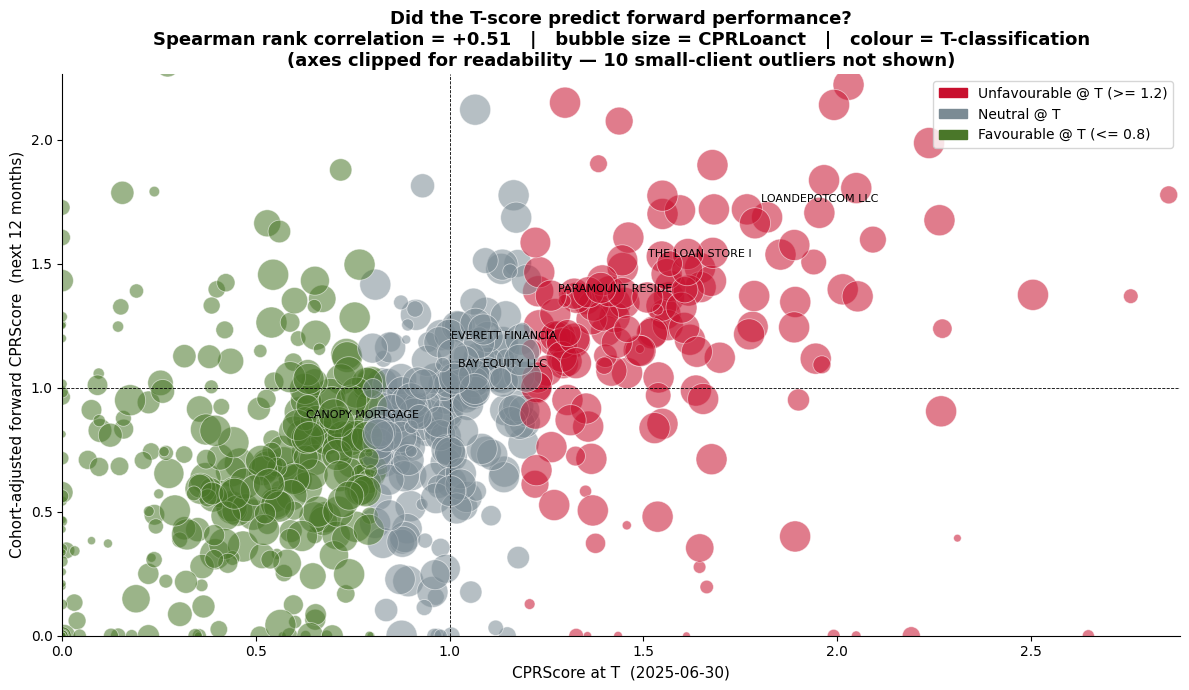

In [22]:
fig, ax = plt.subplots(figsize=(12, 7))

def colour_of(score, lo=LOW_CUTOFF, hi=HIGH_CUTOFF):
    if score >= hi:  return RED
    if score <= lo:  return GREEN
    return GRAY

colours = q1_ok['CPRScore'].apply(colour_of).values
sizes = np.clip(q1_ok['CPRLoanct'] / 5, 30, 500)

ax.scatter(q1_ok['CPRScore'], q1_ok['ForwardCPRScore'],
           s=sizes, c=colours, alpha=0.55, edgecolor='white', linewidth=0.6)

# Reference lines
ax.axhline(1, color='k', lw=0.6, ls='--')
ax.axvline(1, color='k', lw=0.6, ls='--')

# Clip axes to 5-95 percentile so a few tiny-client outliers don't compress the plot
def _clip(s, lo=2, hi=98):
    lo_v, hi_v = np.percentile(s, [lo, hi])
    return max(0, lo_v * 0.9), hi_v * 1.1

xlo, xhi = _clip(q1_ok['CPRScore'])
ylo, yhi = _clip(q1_ok['ForwardCPRScore'])
# Ensure axis includes the "neutral zone" (0.8–1.2) at minimum
xhi = max(xhi, HIGH_CUTOFF + 0.4); xlo = min(xlo, LOW_CUTOFF - 0.2)
yhi = max(yhi, HIGH_CUTOFF + 0.4); ylo = min(ylo, LOW_CUTOFF - 0.2)
ax.set_xlim(max(0, xlo), xhi); ax.set_ylim(max(0, ylo), yhi)

# Report outlier counts pushed outside the plot
n_outside_x = ((q1_ok['CPRScore'] > xhi) | (q1_ok['CPRScore'] < xlo)).sum()
n_outside_y = ((q1_ok['ForwardCPRScore'] > yhi) | (q1_ok['ForwardCPRScore'] < ylo)).sum()

ax.set_xlabel(f'CPRScore at T  ({T_REPORT})')
ax.set_ylabel(f'Cohort-adjusted forward CPRScore  (next {FORWARD_MONTHS} months)')
subtitle = (f'Spearman rank correlation = {sp_rel:+.2f}   |   '
            f'bubble size = CPRLoanct   |   colour = T-classification')
if n_outside_x or n_outside_y:
    subtitle += f'\n(axes clipped for readability — {max(n_outside_x, n_outside_y)} small-client outliers not shown)'
ax.set_title(f'Did the T-score predict forward performance?\n{subtitle}')

import matplotlib.patches as mp
handles = [
    mp.Patch(color=RED,   label=f'Unfavourable @ T (>= {HIGH_CUTOFF})'),
    mp.Patch(color=GRAY,  label='Neutral @ T'),
    mp.Patch(color=GREEN, label=f'Favourable @ T (<= {LOW_CUTOFF})'),
]
ax.legend(handles=handles, loc='upper right', frameon=True)

# Annotate 5 biggest clients (in the visible window)
visible = q1_ok[(q1_ok['CPRScore'].between(xlo, xhi)) & (q1_ok['ForwardCPRScore'].between(ylo, yhi))]
for _, r in visible.nlargest(6, 'CPRLoanct').iterrows():
    ax.annotate(str(r['Client'])[:16], (r['CPRScore'], r['ForwardCPRScore']),
                fontsize=8, ha='center', xytext=(0, 8), textcoords='offset points')

plt.tight_layout(); plt.show()

### 2.7 — Decile monotonicity chart

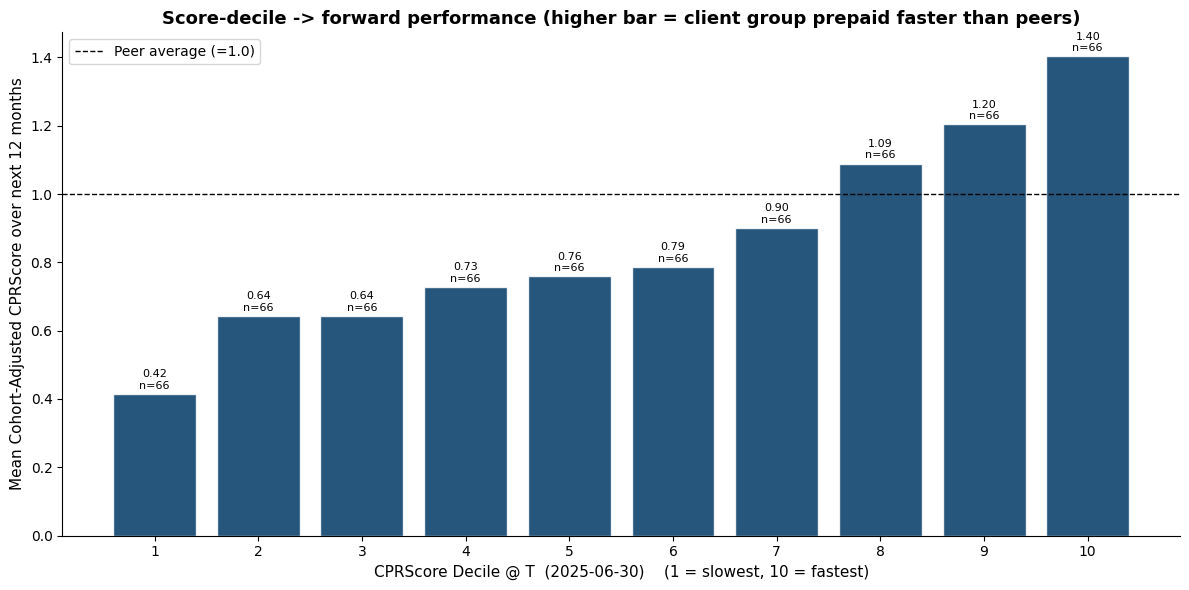

In [10]:
fig, ax = plt.subplots(figsize=(12, 6))
x = decile['CPRScore_Decile'].values
y = decile['ForwardCPRScore_mean'].values
ax.bar(x, y, color=NAVY, alpha=0.85, edgecolor='white')

ax.axhline(1.0, color='k', ls='--', lw=1, label='Peer average (=1.0)')
ax.set_xlabel(f'CPRScore Decile @ T  ({T_REPORT})    (1 = slowest, 10 = fastest)')
ax.set_ylabel(f'Mean Cohort-Adjusted CPRScore over next {FORWARD_MONTHS} months')
ax.set_title('Score-decile -> forward performance (higher bar = client group prepaid faster than peers)')
ax.set_xticks(x)
for xi, yi, n in zip(x, y, decile['n_clients']):
    ax.text(xi, yi + 0.015, f'{yi:.2f}\nn={n}', ha='center', fontsize=8)
ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

### 2.8 — Why cohort-adjustment matters (the "hidden outperformance" comparison)

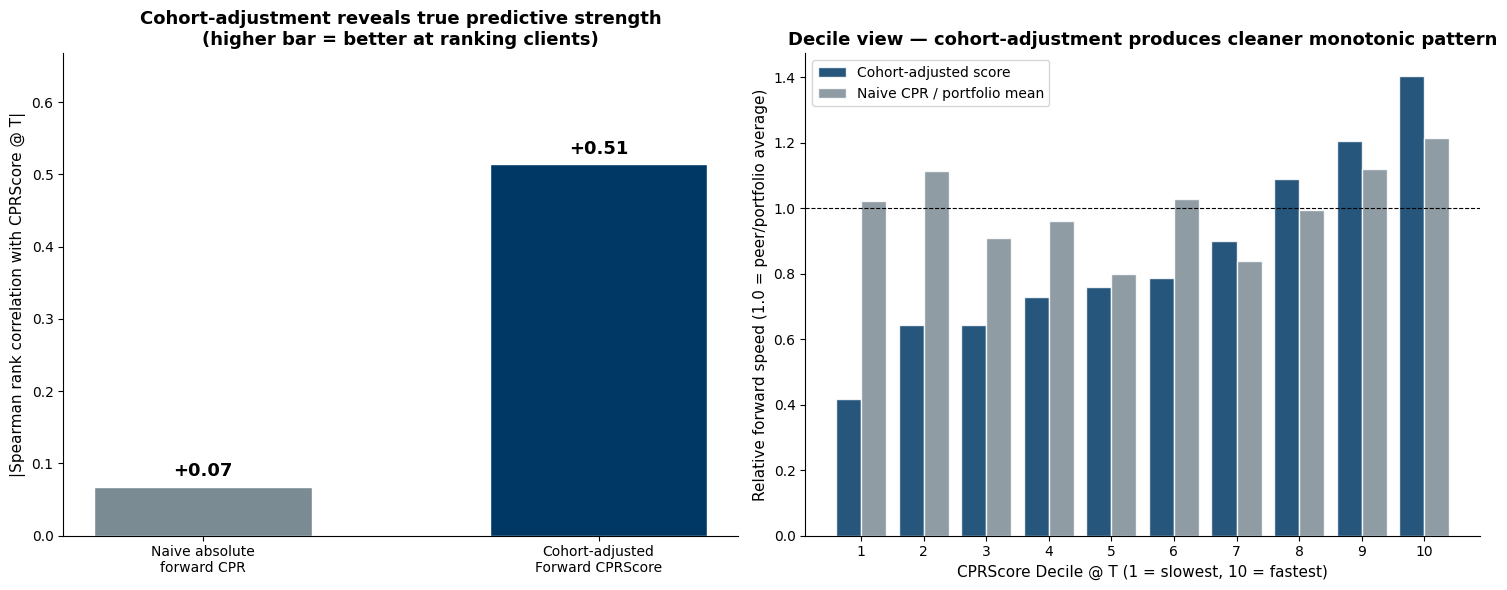

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# LEFT: correlation comparison
axL = axes[0]
labels = ['Naive absolute\nforward CPR', 'Cohort-adjusted\nForward CPRScore']
values = [abs(sp_naive), abs(sp_rel)]
cols   = [GRAY, NAVY]
bars = axL.bar(labels, values, color=cols, width=0.55, edgecolor='white')
for bar, v in zip(bars, values):
    axL.text(bar.get_x() + bar.get_width()/2, v + 0.015, f'{v:+.2f}',
             ha='center', fontsize=13, fontweight='bold')
axL.set_ylabel('|Spearman rank correlation with CPRScore @ T|')
axL.set_ylim(0, max(max(values) * 1.30, 0.1))
axL.set_title('Cohort-adjustment reveals true predictive strength\n'
              '(higher bar = better at ranking clients)')

# RIGHT: decile means -- cohort-adjusted vs naive (rescaled)
axR = axes[1]
w = 0.4
x = decile['CPRScore_Decile'].values
axR.bar(x - w/2, decile['ForwardCPRScore_mean'], w, color=NAVY,
        label='Cohort-adjusted score', alpha=0.85, edgecolor='white')
port_mean_naive = q1_ok['ActualCPR_fwd_naive'].mean()
naive_scaled = decile['NaiveCPR_mean'] / port_mean_naive if port_mean_naive else decile['NaiveCPR_mean']
axR.bar(x + w/2, naive_scaled, w, color=GRAY,
        label='Naive CPR / portfolio mean', alpha=0.85, edgecolor='white')
axR.axhline(1.0, color='k', ls='--', lw=0.8)
axR.set_xticks(x)
axR.set_xlabel(f'CPRScore Decile @ T (1 = slowest, 10 = fastest)')
axR.set_ylabel('Relative forward speed (1.0 = peer/portfolio average)')
axR.set_title('Decile view — cohort-adjustment produces cleaner monotonic pattern')
axR.legend(loc='upper left')

plt.tight_layout(); plt.show()

### 2.9 — Case studies for CRT

Real clients across the score spectrum, shown three ways:

- **Case A** — biggest Unfavourable clients @ T (we told CRT their loans would prepay faster than peers — did they?)
- **Case B** — biggest Favourable clients @ T (we told CRT their loans would prepay slower than peers — did they?)
- **Case C** — clients where cohort-adjustment reveals outperformance the naive absolute-CPR view would have hidden

Read the rows: **Fwd CPRScore** > 1 means the client actually prepaid faster than their peer cohort mix; < 1 means slower. Compare **Naive rank** vs **Peer-adj rank** — a big gap means cohort-mix matters for that client.

In [23]:
q1_ok['Naive_Rank_pct']  = q1_ok['ActualCPR_fwd_naive'].rank(pct=True) * 100
q1_ok['Cohort_Rank_pct'] = q1_ok['ForwardCPRScore'].rank(pct=True)      * 100
q1_ok['Rank_Delta']      = q1_ok['Cohort_Rank_pct'] - q1_ok['Naive_Rank_pct']

cases_A = q1_ok[q1_ok['CPRScore'] >= HIGH_CUTOFF].nlargest(4, 'CPRLoanct').assign(Case='A. Unfavourable @ T')
cases_B = q1_ok[q1_ok['CPRScore'] <= LOW_CUTOFF ].nlargest(4, 'CPRLoanct').assign(Case='B. Favourable @ T')

# Case C — biggest positive Rank_Delta clients (naive view under-rated their speed),
# NOT already appearing in Case A/B
_ab_clients = set(cases_A['Client']).union(cases_B['Client'])
cases_C = (q1_ok[(q1_ok['Rank_Delta'] > 15) & (~q1_ok['Client'].isin(_ab_clients))]
           .nlargest(3, 'CPRLoanct')
           .assign(Case='C. Cohort-hidden outperformance'))

case_df = pd.concat([cases_A, cases_B, cases_C], ignore_index=True)
show_cols = ['Case', 'Client', 'CPRLoanct', 'CPRScore', 'ForwardCPRScore',
             'ActualCPR_fwd_naive', 'ActualCPR_fwd', 'ModelCPR_fwd',
             'Naive_Rank_pct', 'Cohort_Rank_pct']
case_out = case_df[show_cols].copy()
case_out.columns = ['Case', 'Client', 'LoanCt @ T', 'CPRScore @ T', 'Fwd CPRScore',
                    'Naive Fwd CPR', 'Fwd Actual CPR (cohort loans)', 'Peer Fwd CPR',
                    'Naive rank %', 'Peer-adj rank %']

fmt = {
    'LoanCt @ T':                    '{:,.0f}',
    'CPRScore @ T':                  '{:.2f}',
    'Fwd CPRScore':                  '{:.2f}',
    'Naive Fwd CPR':                 '{:.1%}',
    'Fwd Actual CPR (cohort loans)': '{:.1%}',
    'Peer Fwd CPR':                  '{:.1%}',
    'Naive rank %':                  '{:.0f}',
    'Peer-adj rank %':               '{:.0f}',
}
print(f'{len(case_out)} case-study clients:')
case_out.style.format(fmt).hide(axis='index')

11 case-study clients:


Case,Client,LoanCt @ T,CPRScore @ T,Fwd CPRScore,Naive Fwd CPR,Fwd Actual CPR (cohort loans),Peer Fwd CPR,Naive rank %,Peer-adj rank %
A. Unfavourable @ T,THE LOAN STORE INC,"147,638",1.65,1.48,11.4%,6.3%,4.3%,51,91
A. Unfavourable @ T,PARAMOUNT RESIDENTIAL MORTGAGE GROUP INC,"125,870",1.43,1.34,9.8%,6.8%,5.1%,42,85
A. Unfavourable @ T,LOANDEPOTCOM LLC,"110,773",1.95,1.71,15.6%,7.6%,4.5%,69,95
A. Unfavourable @ T,NFM LENDING LLC,"99,567",1.57,1.41,8.5%,6.9%,4.9%,34,89
B. Favourable @ T,CANOPY MORTGAGE LLC,"155,734",0.78,0.83,6.2%,4.8%,5.8%,18,49
B. Favourable @ T,NJ LENDERS CORP,"78,535",0.79,1.02,5.1%,4.4%,4.3%,13,64
B. Favourable @ T,JLB CORPORATION,"49,974",0.75,0.95,7.2%,7.9%,8.3%,24,58
B. Favourable @ T,ROYAL UNITED MORTGAGE LLC,"46,374",0.60,0.64,11.5%,14.3%,22.3%,52,35
C. Cohort-hidden outperformance,EVERETT FINANCIAL INC DBA SUPREME LENDING,"221,861",1.14,1.15,7.1%,7.9%,6.9%,23,74
C. Cohort-hidden outperformance,BAY EQUITY LLC,"118,628",1.14,1.04,7.3%,6.9%,6.6%,25,66


## 3. Q2 — Rank Stability Test

Rerun the CPRScore at two dates H months apart and measure how many clients change classification (Favourable / Neutral / Unfavourable).

### 3.1 — Score clients at T1 and T2 (reuse cached T-score where possible)

In [13]:
def eomonth_off(d, m): return DateHelpers.eomonth(d, m)

T1 = STABILITY_T1
T2_base = eomonth_off(T1, STABILITY_H_MONTHS)

scored_cache = {}

def score_at(dt):
    if dt in scored_cache:
        return scored_cache[dt]
    if dt == T_REPORT:
        scored_cache[dt] = client_scores_T.copy()
        return scored_cache[dt]
    print(f'  Running reporter at {dt} ...')
    r = B2BPricingReporter(engine).load(report_as_of_dt=dt)
    m = r.run_all_metrics(product='All')
    cs = (m[m['MetricName'] == 'Client']
          [['MetricValue', 'CPRLoanct', 'FundedLoanAmt', 'ActualCPR', 'ModelCPR', 'CPRScore']]
          .rename(columns={'MetricValue': 'Client'})
          .reset_index(drop=True))
    scored_cache[dt] = cs
    return cs

print(f'Base stability pair: T1 = {T1}  ->  T2 = {T2_base}')
scored_T1 = score_at(T1)
scored_T2 = score_at(T2_base)
print(f'Clients @ T1: {len(scored_T1):,}   |   Clients @ T2: {len(scored_T2):,}')

Base stability pair: T1 = 2024-06-30  ->  T2 = 2025-06-30
  Running reporter at 2024-06-30 ...
Report as of  : 2024-06-30
Funding window: 2023-07-01  →  2024-06-30
Score window  : 1900-01-01  →  2024-06-30
Clients @ T1: 747   |   Clients @ T2: 783


### 3.2 — Confusion matrix (Favourable / Neutral / Unfavourable)

Common client universe (>= 50 loans at both dates): 581


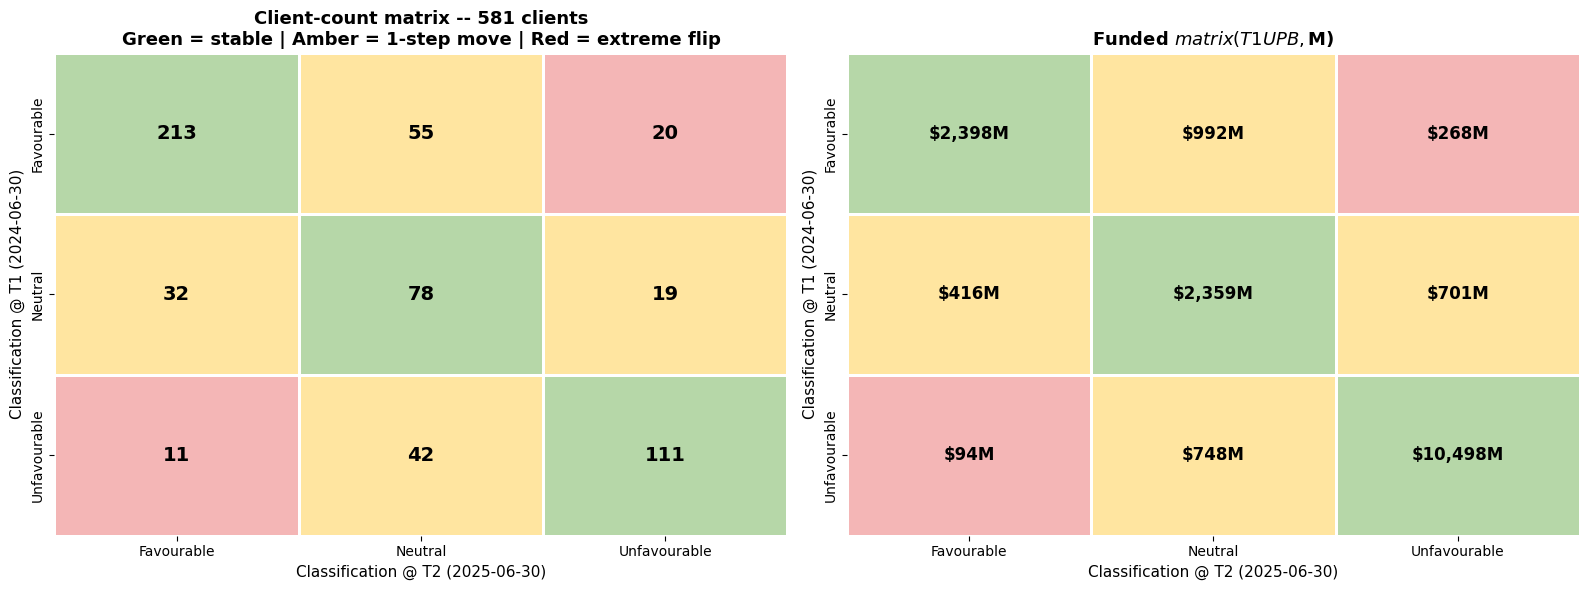


Row totals (T1) and column totals (T2):


,T1_count,T2_count
Favourable,288,256
Neutral,129,175
Unfavourable,164,150


In [15]:
CAT_ORDER = ['Favourable', 'Neutral', 'Unfavourable']

def classify(scores, lo, hi):
    return np.where(scores >= hi, 'Unfavourable',
           np.where(scores <= lo, 'Favourable', 'Neutral'))

def build_pair(sc1, sc2, lo, hi, min_loans):
    m = sc1[['Client','CPRScore','CPRLoanct','FundedLoanAmt']].merge(
        sc2[['Client','CPRScore','CPRLoanct','FundedLoanAmt']],
        on='Client', suffixes=('_1','_2'), how='inner')
    m = m[(m['CPRLoanct_1'] >= min_loans) & (m['CPRLoanct_2'] >= min_loans)].copy()
    m['Class_1'] = classify(m['CPRScore_1'], lo, hi)
    m['Class_2'] = classify(m['CPRScore_2'], lo, hi)
    return m

pair = build_pair(scored_T1, scored_T2, LOW_CUTOFF, HIGH_CUTOFF, MIN_STABILITY_LOANS)
print(f'Common client universe (>= {MIN_STABILITY_LOANS} loans at both dates): {len(pair):,}')

cm_ct  = (pd.crosstab(pair['Class_1'], pair['Class_2'])
            .reindex(index=CAT_ORDER, columns=CAT_ORDER, fill_value=0))
cm_upb = (pair.pivot_table(index='Class_1', columns='Class_2',
                           values='FundedLoanAmt_1', aggfunc='sum', fill_value=0)
              .reindex(index=CAT_ORDER, columns=CAT_ORDER, fill_value=0))

# Custom colour matrix: diagonal = green (stable = good), extreme flips = red (bad),
# adjacent flips = amber. Colour has semantic meaning, values printed as annotations.
def _semantic_colour_mask(mat):
    """Return a 3x3 array of colour codes: 0=diag(stable), 1=adjacent flip, 2=extreme flip."""
    labels = list(mat.index)
    m = np.zeros_like(mat.values, dtype=float)
    for i, r in enumerate(labels):
        for j, c in enumerate(labels):
            if i == j:
                m[i, j] = 0.0        # stable (diagonal) -> green
            elif {r, c} == {'Favourable', 'Unfavourable'}:
                m[i, j] = 1.0        # extreme flip -> red
            else:
                m[i, j] = 0.5        # adjacent flip -> amber
    return m

from matplotlib.colors import LinearSegmentedColormap
semantic_cmap = LinearSegmentedColormap.from_list(
    'stability', [(0.0, '#B6D7A8'), (0.5, '#FFE5A0'), (1.0, '#F4B6B6')]
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# LEFT: client count
mask_ct = _semantic_colour_mask(cm_ct)
sns.heatmap(pd.DataFrame(mask_ct, index=CAT_ORDER, columns=CAT_ORDER),
            annot=cm_ct.values, fmt='d', cmap=semantic_cmap,
            cbar=False, ax=axes[0], linewidths=1, linecolor='white',
            vmin=0, vmax=1,
            annot_kws={'fontsize': 14, 'fontweight': 'bold', 'color': 'black'})
axes[0].set_xlabel(f'Classification @ T2 ({T2_base})')
axes[0].set_ylabel(f'Classification @ T1 ({T1})')
axes[0].set_title(f'Client-count matrix -- {len(pair):,} clients\n'
                  f'Green = stable | Amber = 1-step move | Red = extreme flip')

# RIGHT: UPB $
mask_upb = _semantic_colour_mask(cm_upb)
cm_upb_m = (cm_upb/1e6).round(1)
annot_upb = cm_upb_m.map(lambda v: f'${v:,.0f}M')
sns.heatmap(pd.DataFrame(mask_upb, index=CAT_ORDER, columns=CAT_ORDER),
            annot=annot_upb, fmt='', cmap=semantic_cmap,
            cbar=False, ax=axes[1], linewidths=1, linecolor='white',
            vmin=0, vmax=1,
            annot_kws={'fontsize': 12, 'fontweight': 'bold', 'color': 'black'})
axes[1].set_xlabel(f'Classification @ T2 ({T2_base})')
axes[1].set_ylabel(f'Classification @ T1 ({T1})')
axes[1].set_title('Funded $ matrix (T1 UPB, $M)')

plt.tight_layout(); plt.show()

print('\nRow totals (T1) and column totals (T2):')
pd.DataFrame({'T1_count': cm_ct.sum(axis=1), 'T2_count': cm_ct.sum(axis=0)})

### 3.3 — Stability summary statistics

In [16]:
from sklearn.metrics import cohen_kappa_score

def flip_stats(cm):
    tot = cm.values.sum()
    diag = np.trace(cm.values)
    extreme = cm.loc['Favourable','Unfavourable'] + cm.loc['Unfavourable','Favourable']
    adj = tot - diag - extreme
    return dict(total=tot, stable=diag, adj=adj, extreme=extreme)

f_ct  = flip_stats(cm_ct)
f_upb = flip_stats(cm_upb)

cat_map = {'Favourable':0, 'Neutral':1, 'Unfavourable':2}
kappa    = cohen_kappa_score(pair['Class_1'], pair['Class_2'])
w_kappa  = cohen_kappa_score(pair['Class_1'].map(cat_map),
                             pair['Class_2'].map(cat_map), weights='quadratic')
sp_pair, _ = spearmanr(pair['CPRScore_1'], pair['CPRScore_2'])

summary = pd.DataFrame([
    ['Same classification (stable)',      f_ct['stable']  / f_ct['total'],  f_upb['stable']  / f_upb['total']],
    ['Adjacent flip (Neutral involved)',  f_ct['adj']     / f_ct['total'],  f_upb['adj']     / f_upb['total']],
    ['Extreme flip (Fav <-> Unfav)',      f_ct['extreme'] / f_ct['total'],  f_upb['extreme'] / f_upb['total']],
], columns=['Outcome', '% of clients', '% of T1 UPB'])
summary_disp = summary.style.format({'% of clients': '{:.1%}', '% of T1 UPB': '{:.1%}'}).hide(axis='index')

print('=' * 74)
print(f'Q2 -- RANK STABILITY   (T1 = {T1}  ->  T2 = {T2_base},  h = {STABILITY_H_MONTHS} months)')
print('=' * 74)
print(f'Universe                                : {f_ct["total"]:,} clients')
print(f'                                          ${cm_upb.values.sum()/1e9:.2f}B UPB @ T1')
print()
print(f"Cohen's kappa (chance-corrected)        : {kappa:+.2f}")
print(f"Weighted kappa (extreme flips penalised): {w_kappa:+.2f}")
print(f"Rank correlation of CPRScore T1 vs T2   : {sp_pair:+.2f}")
print()
print('Transition breakdown:')
summary_disp

Q2 -- RANK STABILITY   (T1 = 2024-06-30  ->  T2 = 2025-06-30,  h = 12 months)
Universe                                : 581 clients
                                          $18.48B UPB @ T1

Cohen's kappa (chance-corrected)        : +0.52
Weighted kappa (extreme flips penalised): +0.67
Rank correlation of CPRScore T1 vs T2   : +0.69

Transition breakdown:


Outcome,% of clients,% of T1 UPB
Same classification (stable),69.2%,82.6%
Adjacent flip (Neutral involved),25.5%,15.5%
Extreme flip (Fav <-> Unfav),5.3%,2.0%


### 3.4 — Sensitivity of stability to cutoff choice

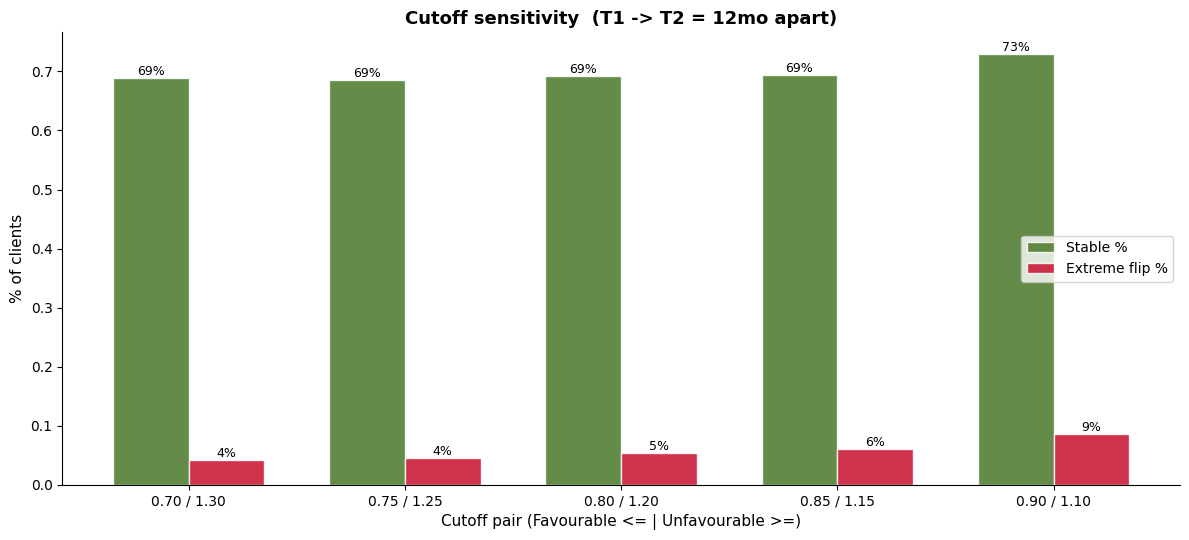

Cutoff (Fav <= / Unfav >=),Fav @ T1,Unfav @ T1,Stable %,Extreme flip %
0.70 / 1.30,256,134,68.8%,4.1%
0.75 / 1.25,270,153,68.5%,4.5%
0.80 / 1.20,288,164,69.2%,5.3%
0.85 / 1.15,304,182,69.4%,6.0%
0.90 / 1.10,321,202,73.0%,8.6%


In [17]:
rows = []
for lo, hi in CUTOFF_GRID:
    pp = pair.copy()
    pp['C1'] = classify(pp['CPRScore_1'], lo, hi)
    pp['C2'] = classify(pp['CPRScore_2'], lo, hi)
    n = len(pp)
    n_stable  = (pp['C1'] == pp['C2']).sum()
    n_extreme = (((pp['C1']=='Favourable') & (pp['C2']=='Unfavourable')) |
                 ((pp['C1']=='Unfavourable') & (pp['C2']=='Favourable'))).sum()
    rows.append({
        'Cutoff (Fav <= / Unfav >=)': f'{lo:.2f} / {hi:.2f}',
        'Fav @ T1':   int((pp['C1']=='Favourable').sum()),
        'Unfav @ T1': int((pp['C1']=='Unfavourable').sum()),
        'Stable %':   n_stable / n,
        'Extreme flip %': n_extreme / n,
    })
sens_cutoff = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(12, 5.5))
x = np.arange(len(sens_cutoff))
w = 0.35
ax.bar(x - w/2, sens_cutoff['Stable %'],       w, color=GREEN, label='Stable %',
       alpha=0.85, edgecolor='white')
ax.bar(x + w/2, sens_cutoff['Extreme flip %'], w, color=RED,   label='Extreme flip %',
       alpha=0.85, edgecolor='white')
ax.set_xticks(x); ax.set_xticklabels(sens_cutoff['Cutoff (Fav <= / Unfav >=)'])
ax.set_xlabel('Cutoff pair (Favourable <= | Unfavourable >=)')
ax.set_ylabel('% of clients')
ax.set_title(f'Cutoff sensitivity  (T1 -> T2 = {STABILITY_H_MONTHS}mo apart)')
ax.legend(loc='center right')
for xi, v in zip(x - w/2, sens_cutoff['Stable %']):
    ax.text(xi, v+0.005, f'{v:.0%}', ha='center', fontsize=9)
for xi, v in zip(x + w/2, sens_cutoff['Extreme flip %']):
    ax.text(xi, v+0.005, f'{v:.0%}', ha='center', fontsize=9)
plt.tight_layout(); plt.show()

sens_cutoff.style.format({'Stable %': '{:.1%}', 'Extreme flip %': '{:.1%}'}).hide(axis='index')

### 3.5 — Sensitivity of stability to time horizon (months apart)

  Running reporter at 2024-12-31 ...
Report as of  : 2024-12-31
Funding window: 2024-01-01  →  2024-12-31
Score window  : 1900-01-01  →  2024-12-31
  Running reporter at 2025-12-31 ...
Report as of  : 2025-12-31
Funding window: 2025-01-01  →  2025-12-31
Score window  : 1900-01-01  →  2025-12-31


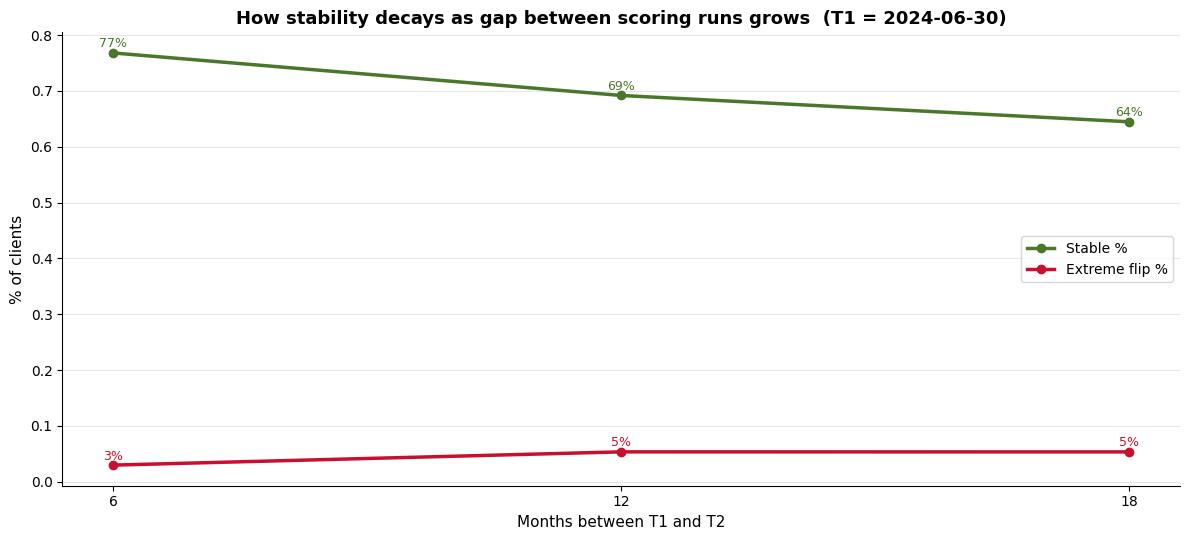

Horizon (months),T2,Clients in pair,Stable %,Extreme flip %
6,2024-12-31,608,76.8%,3.0%
12,2025-06-30,581,69.2%,5.3%
18,2025-12-31,563,64.5%,5.3%


In [18]:
rows = []
for h in HORIZON_GRID:
    Th = eomonth_off(T1, h)
    sc_h = score_at(Th)
    pp = build_pair(scored_T1, sc_h, LOW_CUTOFF, HIGH_CUTOFF, MIN_STABILITY_LOANS)
    if len(pp) == 0:
        continue
    n = len(pp)
    n_stable  = (pp['Class_1'] == pp['Class_2']).sum()
    n_extreme = (((pp['Class_1']=='Favourable') & (pp['Class_2']=='Unfavourable')) |
                 ((pp['Class_1']=='Unfavourable') & (pp['Class_2']=='Favourable'))).sum()
    rows.append({
        'Horizon (months)': h,
        'T2':               str(Th),
        'Clients in pair':  n,
        'Stable %':         n_stable / n,
        'Extreme flip %':   n_extreme / n,
    })
sens_horizon = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(sens_horizon['Horizon (months)'], sens_horizon['Stable %'],
        marker='o', lw=2.5, color=GREEN, label='Stable %')
ax.plot(sens_horizon['Horizon (months)'], sens_horizon['Extreme flip %'],
        marker='o', lw=2.5, color=RED,   label='Extreme flip %')
ax.set_xticks(sens_horizon['Horizon (months)'])
ax.set_xlabel('Months between T1 and T2')
ax.set_ylabel('% of clients')
ax.set_title(f'How stability decays as gap between scoring runs grows  (T1 = {T1})')
ax.legend(loc='center right')
ax.grid(axis='y', alpha=0.3)
for _, r in sens_horizon.iterrows():
    ax.text(r['Horizon (months)'], r['Stable %']+0.01,
            f"{r['Stable %']:.0%}", ha='center', color=GREEN, fontsize=9)
    ax.text(r['Horizon (months)'], r['Extreme flip %']+0.01,
            f"{r['Extreme flip %']:.0%}", ha='center', color=RED, fontsize=9)
plt.tight_layout(); plt.show()

sens_horizon.style.format({'Stable %': '{:.1%}', 'Extreme flip %': '{:.1%}'}).hide(axis='index')

### 3.6 — Extreme flippers (Favourable <-> Unfavourable) — investigate before dismissing the score

In [19]:
flip_mask = (((pair['Class_1']=='Favourable') & (pair['Class_2']=='Unfavourable')) |
             ((pair['Class_1']=='Unfavourable') & (pair['Class_2']=='Favourable')))
flippers = pair[flip_mask].copy()
flippers['Direction'] = np.where(flippers['Class_1']=='Favourable', 'Fav -> Unfav', 'Unfav -> Fav')
flippers = flippers.sort_values('FundedLoanAmt_1', ascending=False)

show_cols = ['Client', 'Direction',
             'CPRScore_1', 'CPRScore_2',
             'CPRLoanct_1', 'CPRLoanct_2',
             'FundedLoanAmt_1']
flip_out = flippers[show_cols].copy()
flip_out.columns = ['Client', 'Direction', 'CPRScore @ T1', 'CPRScore @ T2',
                    'LoanCt @ T1', 'LoanCt @ T2', 'FundedLoanAmt @ T1']

print(f'Extreme flippers: {len(flippers):,} clients')
if len(flippers) > 0:
    print(f'Total T1 UPB in flippers: ${flip_out["FundedLoanAmt @ T1"].sum()/1e6:,.1f}M')
print()
flip_styled = (flip_out.head(20).style
               .format({'CPRScore @ T1':'{:.2f}', 'CPRScore @ T2':'{:.2f}',
                        'LoanCt @ T1':'{:,.0f}', 'LoanCt @ T2':'{:,.0f}',
                        'FundedLoanAmt @ T1':'${:,.0f}'})
               .hide(axis='index'))
flip_styled

Extreme flippers: 31 clients
Total T1 UPB in flippers: $363.0M



Client,Direction,CPRScore @ T1,CPRScore @ T2,LoanCt @ T1,LoanCt @ T2,FundedLoanAmt @ T1
RESICENTRAL LLC,Fav -> Unfav,0.52,1.29,"1,927","4,537","$47,676,014"
INTERCOASTAL MORTGAGE LLC,Fav -> Unfav,0.70,1.23,"3,620","7,543","$46,168,438"
ZIONS BANCORPORATION NATIONAL ASSOCIATION,Fav -> Unfav,0.04,1.64,"1,162","2,500","$29,469,236"
TOMO MORTGAGE LLC,Fav -> Unfav,0.00,1.94,262,"1,694","$28,377,433"
CAMBRIDGE SAVINGS BANK,Fav -> Unfav,0.00,2.27,140,970,"$22,478,011"
TRISTAR FINANCE INC,Unfav -> Fav,88.08,0.35,78,505,"$19,185,455"
LOANUNITEDCOM LLC,Unfav -> Fav,1.60,0.35,355,"1,517","$17,504,085"
MDE HOME LOANS LLC,Fav -> Unfav,0.00,1.40,161,786,"$15,445,769"
FARMERS BANK & TRUST,Fav -> Unfav,0.00,1.38,110,808,"$14,982,736"
FIRST STATE MORTGAGE SERVICES LLC,Unfav -> Fav,1.25,0.77,"3,992","7,250","$11,353,645"


## 4. Executive summary — for the CRT deck

In [20]:
lines = [
    '=' * 74,
    'CPRSCORE VALIDATION -- EXECUTIVE SUMMARY',
    '=' * 74,
    '',
    'Q1 -- DID THE SCORE PREDICT FORWARD PERFORMANCE?',
    f'  Report date         : {T_REPORT}',
    f'  Forward window      : {FORWARD_MONTHS} months  ({T_REPORT} -> {end_fwd_dt})',
    f'  Client universe     : {len(q1_ok):,}  (>= {MIN_CPR_LOANS_Q1} loans at T)',
    '',
    f'  * Cohort-adjusted rank correlation: {sp_rel:+.2f}',
    f'      (this is the number CRT should focus on - see 2.5 / 2.6 / 2.8)',
    f'  * Naive absolute rank correlation : {sp_naive:+.2f}',
    f'      (weaker - proves cohort-adjustment is what makes the score work)',
    f'  * Top-decile vs bottom-decile lift: {top_mean/bot_mean:.2f}x',
    '',
    'Q2 -- HOW STABLE ARE CLIENT CLASSIFICATIONS?',
    f'  T1 -> T2            : {T1} -> {T2_base}  ({STABILITY_H_MONTHS} months apart)',
    f'  Cutoffs             : Favourable <= {LOW_CUTOFF}, Unfavourable >= {HIGH_CUTOFF}',
    f'  Client universe     : {f_ct["total"]:,}  (>= {MIN_STABILITY_LOANS} loans at both dates)',
    '',
    f'  * Same classification (stable): {f_ct["stable"]/f_ct["total"]:.0%} of clients | {f_upb["stable"]/f_upb["total"]:.0%} of T1 UPB',
    f'  * Adjacent flip (via Neutral) : {f_ct["adj"]/f_ct["total"]:.0%} of clients | {f_upb["adj"]/f_upb["total"]:.0%} of T1 UPB',
    f'  * Extreme flip (Fav<->Unfav)  : {f_ct["extreme"]/f_ct["total"]:.0%} of clients | {f_upb["extreme"]/f_upb["total"]:.0%} of T1 UPB',
    f'      (CRT primary concern - small % here = score is dependable)',
    '',
    f'  Kappa (chance-corrected agreement) : {kappa:+.2f}',
    f'  Weighted kappa (penalises extremes): {w_kappa:+.2f}',
    f'  Rank correlation across dates      : {sp_pair:+.2f}',
    '',
    '=' * 74,
]
print('\n'.join(lines))

CPRSCORE VALIDATION -- EXECUTIVE SUMMARY

Q1 -- DID THE SCORE PREDICT FORWARD PERFORMANCE?
  Report date         : 2025-06-30
  Forward window      : 12 months  (2025-06-30 -> 2026-06-30)
  Client universe     : 660  (>= 100 loans at T)

  * Cohort-adjusted rank correlation: +0.51
      (this is the number CRT should focus on - see 2.5 / 2.6 / 2.8)
  * Naive absolute rank correlation : +0.07
      (weaker - proves cohort-adjustment is what makes the score work)
  * Top-decile vs bottom-decile lift: 3.38x

Q2 -- HOW STABLE ARE CLIENT CLASSIFICATIONS?
  T1 -> T2            : 2024-06-30 -> 2025-06-30  (12 months apart)
  Cutoffs             : Favourable <= 0.8, Unfavourable >= 1.2
  Client universe     : 581  (>= 50 loans at both dates)

  * Same classification (stable): 69% of clients | 83% of T1 UPB
  * Adjacent flip (via Neutral) : 25% of clients | 15% of T1 UPB
  * Extreme flip (Fav<->Unfav)  : 5% of clients | 2% of T1 UPB
      (CRT primary concern - small % here = score is dependabl

## 5. Export raw tables to Excel

In [24]:
os.makedirs(OUTPUT_PATH, exist_ok=True)
full_out = os.path.join(OUTPUT_PATH, OUTPUT_FILE)
with pd.ExcelWriter(full_out, engine='xlsxwriter') as w:
    q1_ok.to_excel(w,   sheet_name='Q1_client_forward_scores', index=False)
    decile.to_excel(w,  sheet_name='Q1_deciles', index=False)
    case_out.to_excel(w, sheet_name='Q1_case_studies', index=False)
    cm_ct.to_excel(w,   sheet_name='Q2_confusion_count')
    (cm_upb/1e6).round(2).to_excel(w, sheet_name='Q2_confusion_upb_$M')
    sens_cutoff.to_excel(w,  sheet_name='Q2_sens_cutoff',  index=False)
    sens_horizon.to_excel(w, sheet_name='Q2_sens_horizon', index=False)
    flip_out.to_excel(w, sheet_name='Q2_extreme_flippers', index=False)
print(f'Saved: {full_out}')

Saved: E:\Development\Shashi\B2B-Pricing-Model\Cohort_Analysis\B2B_reporting_raw\CPR_score_justification_20250630.xlsx
